# DDS-8555 Assignment 8, Notebook 1 of 3: Store Sales Time Series Forecasting (ETS and ARIMA)
**Nathan Weber** · National University · DDS-8555: Predictive Analysis · Dr. Alexander Watt

**How to run:** Runtime → Run all. Approve the Google Drive prompt. When the upload button appears, choose the Kaggle Store Sales zip (only the first time). The two Kaggle submission files download automatically and are also saved to Drive → DDS8555 → output.

Assignment 8 has three notebooks, one per competition: (1) Store Sales, this one; (2) House Prices; (3) San Francisco Crime. Each runs on its own.

| Requirement | Where |
|---|---|
| One ETS model, submitted to Kaggle | Part 3, Model 1 |
| One ARIMA model, submitted to Kaggle | Part 3, Model 2 |
| Interpret the time series models | Parts 2 and 5 |
| Investigate assumptions | Part 4 (stationarity, residual autocorrelation, normality, variance) |
| Evidence of submission | Screenshot in the paper's appendix |

In [1]:
# ==============================================================================
# DDS-8555 Predictive Analysis | Assignment 8 (Notebook 1 of 3): Build & Evaluate Time Series Models: Store Sales (ETS, ARIMA)
# National University | Instructor: Dr. Alexander V. Watt | Author: Nathan Weber
# Notebook: DDS8555_ASGN8Part1of3_StoreSales_NWeber.ipynb
# Paper:    WeberN_DDS8555-910002634_ASGN8Part1of1.docx  (the written report; code is not reproduced there)
# Version:  v1.2, 2026-11-09 (see the change log at the end of this cell)
# ------------------------------------------------------------------------------
# RUN:      Google Colab -> Runtime -> Run all (also runs locally with Python 3.10+).
#           Needs: numpy, pandas, matplotlib, statsmodels, scipy.
# INPUTS:   Kaggle 'Store Sales - Time Series Forecasting' (store-sales-time-series-forecasting):
#           train.csv, test.csv, sample_submission.csv (and the other CSVs, or the zip) in
#           Google Drive/MyDrive/DDS8555/storesales.
#           https://www.kaggle.com/competitions/store-sales-time-series-forecasting
# OUTPUTS:  Drive/MyDrive/DDS8555/output: A8_store_model1_ets.csv, A8_store_model2_arima.csv, A8_store_fig_series.png, A8_store_fig_forecast.png, A8_store_fig_resid.png, A8_store_results.json
# ------------------------------------------------------------------------------
# QUESTION: Forecast 16 days of unit sales for 1,782 store-by-product-family series with one exponential smoothing (ETS) model and one ARIMA model, using a top-down approach: forecast the 33 product-family totals, then split each total across stores by recent store shares.
# TARGET:   sales (units). Kaggle metric = RMSLE, so models are fit to log(1 + sales) and
#           forecasts are transformed back.
# CLEANING: no rows dropped. Days when every store is closed (Jan 1) are removed from the family
#           totals; history starts 2015-08-01 (two years), where all families are being recorded.
# VALIDATION:time-ordered holdout: models are fit through 2017-07-30 and scored on the last 16 days
#           of training data (2017-07-31 to 2017-08-15), the same length as Kaggle's test window;
#           a seasonal naive forecast (same weekday last week) is the baseline. A second window,
#           the 16 days before that, repeats the comparison. Final models are refit through
#           2017-08-15 before forecasting the test window.
# SEEDS:    none needed (all fits are deterministic).
# DEPENDS ON: None. Independent of the other two A8 notebooks.
# CHECKS:   input SHA-256 fingerprints, row counts, column names, and package versions
#           are printed below and at the end, so a re-run can be compared line by line.
# ------------------------------------------------------------------------------
# CHANGE LOG:
#   v1.0  2026-10-28  First version.
#   v1.1  2026-11-02  Added error bars for the holdout: RMSLE by day and by family, the
#                     paired ETS-vs-ARIMA difference with its standard error, and a second
#                     16-day holdout window (2017-07-15 to 07-30); ETS trend choice counted;
#                     data-provenance note added.
#   v1.2  2026-11-09  Assumption-check cell: the variance ratio is left blank (NaN) for a
#                     family whose first-half residuals are constant, instead of dividing
#                     by zero (stopped the v1.1 run in Colab). No model or forecast changed.
# ==============================================================================

In [2]:
## ---- 0. Setup and imports ------------------------------------------------------
# ---- 0. Setup: runs in Google Colab (also runs locally) ----
import sys, os, glob, zipfile, json, time, warnings, hashlib, datetime
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/DDS8555"
    !pip -q install --no-deps ISLP
else:
    BASE = os.environ.get("DDS8555_BASE", ".")
DATA_DIR = os.path.join(BASE, "storesales")
OUT_DIR = os.path.join(BASE, "output")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 120); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}          # every number the paper uses is stored here and printed at the end
T0 = time.time()

def unzip_all(folder):
    """Extract every zip in the folder (and zips inside zips), once."""
    for _ in range(2):
        for z in glob.glob(os.path.join(folder, "*.zip")):
            with zipfile.ZipFile(z) as f:
                for name in f.namelist():
                    target = os.path.join(folder, os.path.basename(name))
                    if name.endswith("/") or os.path.exists(target):
                        continue
                    with f.open(name) as src, open(target, "wb") as dst:
                        dst.write(src.read())

def get_files(need):
    """Make sure every file in `need` is in DATA_DIR; in Colab, ask for an upload once if not."""
    unzip_all(DATA_DIR)
    if IN_COLAB and not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in need):
        print("Choose the Kaggle download (the zip, or the CSV files):")
        for name, data in files.upload().items():
            open(os.path.join(DATA_DIR, name), "wb").write(data)
        unzip_all(DATA_DIR)
    missing = [f for f in need if not os.path.exists(os.path.join(DATA_DIR, f))]
    assert not missing, f"Missing files in {DATA_DIR}: {missing}  (found: {sorted(os.listdir(DATA_DIR))})"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def fingerprint(names):
    fp = {f: sha256(os.path.join(DATA_DIR, f)) for f in names}
    print("Run started (UTC):", datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"))
    for f, h in fp.items():
        print(f"SHA-256 {f:<28} {h}")
    return fp

def save_fig(name):
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, name), dpi=150); plt.show()

def download(path):
    if IN_COLAB:
        files.download(path)

Mounted at /content/drive


## Part 1. Load the data
`train.csv` holds daily unit sales from 2013-01-01 to 2017-08-15 for every store (54) and product family (33): 1,782 series. `test.csv` covers 2017-08-16 to 2017-08-31 and gives only the number of items on promotion. The other files (oil prices, holidays, transactions, store details) are loaded for the record and summarized, but the models use only sales history and promotions, which are known for the test days.

**Where the data come from:** one grocery chain (Corporación Favorita) in Ecuador, January 2013 to August 2017. The history includes the April 16, 2016 earthquake, and holidays and oil prices are not modeled, so the results describe this chain in this period and may not carry over to other retailers, countries, or years.

In [3]:
## ---- 1. Load, check, and fingerprint the data ----------------------------------
NEED = ["train.csv", "test.csv", "sample_submission.csv"]
get_files(NEED)
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"), parse_dates=["date"])
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"), parse_dates=["date"])
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
print("train:", train.shape, train.date.min().date(), "to", train.date.max().date())
print("test: ", test.shape, test.date.min().date(), "to", test.date.max().date())
print("stores:", train.store_nbr.nunique(), " families:", train.family.nunique(), " series:", train.groupby(["store_nbr", "family"]).ngroups)
assert {"id", "date", "store_nbr", "family", "sales", "onpromotion"} <= set(train.columns)
assert len(test) == len(sample)
FP = fingerprint(NEED)
print(f"missing values: train {int(train.isna().sum().sum())}, test {int(test.isna().sum().sum())}")
print(f"rows with zero sales: {(train.sales == 0).mean():.1%}; negative sales: {int((train.sales < 0).sum())}")
all_dates = pd.date_range(train.date.min(), train.date.max())
missing_days = sorted(set(all_dates.date) - set(train.date.dt.date))
print("calendar days missing from train (stores closed):", missing_days)
zero_series = train.groupby(["store_nbr", "family"]).sales.sum().eq(0)
print(f"store-family series that never sell: {int(zero_series.sum())} of {len(zero_series)}")
for extra in ("oil.csv", "holidays_events.csv", "transactions.csv", "stores.csv"):
    pth = os.path.join(DATA_DIR, extra)
    if os.path.exists(pth):
        print(f"{extra}: {pd.read_csv(pth).shape}")
RESULTS["data"] = {"n_train": len(train), "n_test": len(test), "start": str(train.date.min().date()), "end": str(train.date.max().date()),
                   "test_start": str(test.date.min().date()), "test_end": str(test.date.max().date()),
                   "series": int(train.groupby(["store_nbr", "family"]).ngroups), "families": int(train.family.nunique()),
                   "stores": int(train.store_nbr.nunique()), "zero_share": float((train.sales == 0).mean()),
                   "never_sell": int(zero_series.sum()), "missing_days": [str(d) for d in missing_days], "sha256": FP}

train: (3000888, 6) 2013-01-01 to 2017-08-15
test:  (28512, 5) 2017-08-16 to 2017-08-31
stores: 54  families: 33  series: 1782
Run started (UTC): 2026-11-10 16:44
SHA-256 train.csv                    99a1b7f4241821df10fa71f23abdd71c634f71f901e3cab1400c0f0c583f862c
SHA-256 test.csv                     087ec1ecec76dbba9ea2adb48b8b2fd527c7c59adb82b0dfb9f6f82739400d26
SHA-256 sample_submission.csv        17505ec561d9bc64a3c10c3eb00474becf162d9053cebf014a58a6c82ed530c4
missing values: train 0, test 0
rows with zero sales: 31.3%; negative sales: 0
calendar days missing from train (stores closed): [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]
store-family series that never sell: 53 of 1782
oil.csv: (1218, 2)
holidays_events.csv: (350, 6)
transactions.csv: (83488, 3)
stores.csv: (54, 5)


## Part 2. Family-level series: what the models have to capture
Forecasting 1,782 thin, noisy store-level series one by one is slow and fragile, so both models forecast the 33 product-family totals (summed over stores) on the log(1 + sales) scale. That is the scale the RMSLE metric uses, and it turns multiplicative weekly swings into additive ones. Each family forecast is then split across stores by each store's share of that family over the last 28 days (a "top-down" forecast). The plots and the STL decomposition below show the trend, the strong weekly cycle, and the change in variance that the models must handle.

weekday index (all families, 1 = average): {0: 0.961, 1: 0.9, 2: 0.942, 3: 0.791, 4: 0.929, 5: 1.189, 6: 1.288}
STL strength: weekly seasonality 0.73, trend 0.51 (0 = none, 1 = dominant)


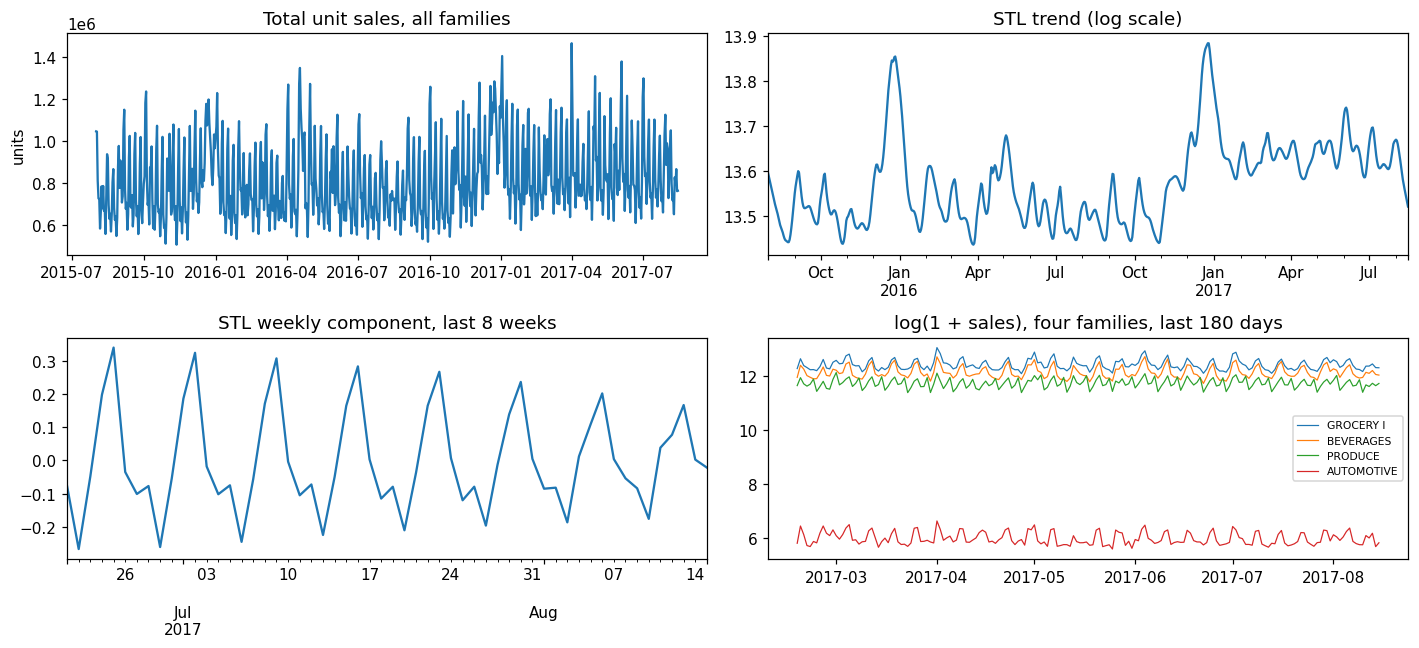

In [4]:
## ---- 2. Family-level series, STL decomposition, weekly pattern -----------------
from statsmodels.tsa.seasonal import STL
START = pd.Timestamp("2015-08-01")
fam_daily = train[train.date >= START].groupby(["date", "family"]).sales.sum().unstack("family")
fam_daily = fam_daily.reindex(pd.date_range(START, train.date.max())).drop(index=[d for d in fam_daily.index if d.month == 1 and d.day == 1], errors="ignore")
fam_daily = fam_daily.asfreq("D").interpolate(limit=2).fillna(0)
promo_daily = train[train.date >= START].groupby(["date", "family"]).onpromotion.sum().unstack("family").reindex(fam_daily.index).fillna(0)
Y = np.log1p(fam_daily); P = np.log1p(promo_daily)
FAMS = list(Y.columns)
total = Y.sum(1)
stl = STL(np.log1p(fam_daily.sum(1)), period=7, robust=True).fit()
dow = fam_daily.sum(1).groupby(fam_daily.index.dayofweek).mean(); dow = dow / dow.mean()
print("weekday index (all families, 1 = average):", dow.round(3).to_dict())
strength_season = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
strength_trend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f"STL strength: weekly seasonality {strength_season:.2f}, trend {strength_trend:.2f} (0 = none, 1 = dominant)")
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
ax[0, 0].plot(fam_daily.sum(1)); ax[0, 0].set_title("Total unit sales, all families"); ax[0, 0].set_ylabel("units")
stl.trend.plot(ax=ax[0, 1], title="STL trend (log scale)")
stl.seasonal[-56:].plot(ax=ax[1, 0], title="STL weekly component, last 8 weeks")
for f in ("GROCERY I", "BEVERAGES", "PRODUCE", "AUTOMOTIVE"):
    if f in Y: ax[1, 1].plot(Y[f][-180:], label=f, lw=.8)
ax[1, 1].legend(fontsize=7); ax[1, 1].set_title("log(1 + sales), four families, last 180 days")
save_fig("A8_store_fig_series.png")
RESULTS["series"] = {"start": str(START.date()), "n_days": len(Y), "weekday_index": dow.round(4).to_dict(),
                     "stl_seasonal_strength": strength_season, "stl_trend_strength": strength_trend}

## Part 3. The two models, a validation holdout, and the Kaggle forecasts
* **Model 1, ETS (exponential smoothing):** Holt-Winters with an additive damped trend and additive weekly seasonality (period 7) on log(1 + sales), fit separately to each family. Damping keeps the trend from running away over 16 days. If a family's series is too flat for a trend, the no-trend version is used instead, chosen by AIC.
* **Model 2, ARIMA:** a seasonal ARIMA, written ARIMA(p,1,q)(1,0,1)₇, with the family's log promotions as an outside regressor (ARIMAX). The (p, q) pair is chosen per family by AIC from a small grid. Promotion counts are known for the test days, so they can be used in the forecast.
* **Baseline:** the seasonal naive forecast, which repeats the same weekday from the last week.

Each model is fit through 2017-07-30 and scored on the final 16 training days, after the same top-down split, against the true store-level sales. A single 16-day window gives one number with no error bar, so the cell also prints (1) the RMSLE for each day and each family, (2) the paired ARIMA-minus-ETS difference with its standard error, and (3) the same comparison on a second window, the 16 days before (fit through 2017-07-14). If the difference between the models is smaller than about two standard errors, or flips between windows, the two models are effectively tied. The final versions are refit on all data through 2017-08-15 to forecast the test window.

In [5]:
## ---- 3a. Fit ETS and ARIMA; two 16-day holdout windows vs. seasonal naive; error bars ---
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
H = 16
cut = Y.index[-H]                                    # first holdout day
def fit_ets(y):
    best = None
    for trend, damped in (("add", True), (None, False)):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")              # optimizer notes; the AIC comparison handles weak fits
                m = ExponentialSmoothing(y, trend=trend, damped_trend=damped, seasonal="add", seasonal_periods=7,
                                         initialization_method="estimated").fit(optimized=True)
            if best is None or m.aic < best.aic:
                best = m
        except Exception:
            pass
    return best
ARIMA_GRID = [(1, 1, 1), (2, 1, 1), (1, 1, 2), (0, 1, 1)]
def fit_arima(y, x):
    best, best_order = None, None
    for order in ARIMA_GRID:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")              # convergence notes; the AIC comparison handles weak fits
                m = SARIMAX(y, exog=x, order=order, seasonal_order=(1, 0, 1, 7), enforce_stationarity=False,
                            enforce_invertibility=False).fit(disp=False, maxiter=200)
            if best is None or m.aic < best.aic:
                best, best_order = m, order
        except Exception:
            pass
    return best, best_order

def family_forecasts(Yfit, Pfit, Pfut, horizon):
    """Return (ETS, ARIMA) family-level forecasts on the log scale, plus fitted models."""
    ets_f, ari_f, ets_m, ari_m, orders = {}, {}, {}, {}, {}
    for f in FAMS:
        y = Yfit[f]
        if y.iloc[-56:].sum() == 0:                      # family not sold recently: forecast zero
            ets_f[f] = ari_f[f] = np.zeros(horizon); continue
        m1 = fit_ets(y); ets_m[f] = m1
        ets_f[f] = np.asarray(m1.forecast(horizon))
        m2, order = fit_arima(y, Pfit[[f]]); ari_m[f] = m2; orders[f] = order
        ari_f[f] = np.asarray(m2.forecast(horizon, exog=Pfut[[f]].values))
    return pd.DataFrame(ets_f), pd.DataFrame(ari_f), ets_m, ari_m, orders

def store_shares(upto):
    recent = train[(train.date > upto - pd.Timedelta(days=28)) & (train.date <= upto)]
    s = recent.groupby(["family", "store_nbr"]).sales.sum()
    return (s / s.groupby(level=0).transform("sum")).fillna(0)

def to_store_level(fam_log_fc, dates, shares, frame):
    """Split family forecasts (log scale) across stores; return predictions aligned to `frame` rows."""
    fam_units = np.expm1(fam_log_fc.clip(lower=0)); fam_units.index = dates
    long = fam_units.stack().rename("fam_units").reset_index().rename(columns={"level_0": "date", "level_1": "family"})
    m = frame[["date", "store_nbr", "family"]].merge(long, on=["date", "family"], how="left")
    sh = shares.rename("share").reset_index()
    m = m.merge(sh, on=["family", "store_nbr"], how="left")
    return (m.fam_units.fillna(0) * m.share.fillna(0)).clip(lower=0).values

def rmsle(y, p):
    return float(np.sqrt(np.mean((np.log1p(y) - np.log1p(p)) ** 2)))

# ---- validation: fit through the day before `cut_day`, forecast the next 16 days, score at store level ----
def validate(cut_day):
    Yfit, Pfit = Y[Y.index < cut_day], P[P.index < cut_day]
    hd = Y.index[Y.index >= cut_day][:H]
    ets_f, ari_f, _, _, ords = family_forecasts(Yfit, Pfit, P.loc[hd], H)
    hold = train[(train.date >= cut_day) & (train.date <= hd[-1])].copy()
    sh = store_shares(cut_day - pd.Timedelta(days=1))
    lw = train[(train.date >= cut_day - pd.Timedelta(days=7)) & (train.date < cut_day)].assign(dow=lambda d: d.date.dt.dayofweek)
    naive = hold.assign(dow=hold.date.dt.dayofweek).merge(lw[["store_nbr", "family", "dow", "sales"]].rename(columns={"sales": "naive"}),
                                                          on=["store_nbr", "family", "dow"], how="left").naive.fillna(0).values
    preds = {"Seasonal naive (baseline)": naive, "Model 1: ETS": to_store_level(ets_f, hd, sh, hold),
             "Model 2: ARIMA": to_store_level(ari_f, hd, sh, hold)}
    return {"hold": hold, "dates": hd, "ets": ets_f, "ari": ari_f, "orders": ords, "preds": preds,
            "rmsle": {k: rmsle(hold.sales.values, v) for k, v in preds.items()}}

def spread(res):
    """RMSLE by day and by family, and the paired ARIMA - ETS difference with its standard error."""
    sq = {k: pd.Series((np.log1p(res["hold"].sales.values) - np.log1p(v)) ** 2, index=res["hold"].index) for k, v in res["preds"].items()}
    out = {}
    for by in ("date", "family"):
        g = {k: np.sqrt(v.groupby(res["hold"][by]).mean()) for k, v in sq.items()}
        d = g["Model 2: ARIMA"] - g["Model 1: ETS"]
        out[by] = {"n": int(len(d)), "rmsle_mean": {k: float(v.mean()) for k, v in g.items()},
                   "rmsle_sd": {k: float(v.std(ddof=1)) for k, v in g.items()},
                   "diff_arima_minus_ets": float(d.mean()), "diff_se": float(d.std(ddof=1) / np.sqrt(len(d))),
                   "arima_better_share": float((d < 0).mean())}
    return out

t0 = time.time()
cut2 = Y.index[-2 * H]                               # first day of the second (earlier) window
V1, V2 = validate(cut), validate(cut2)
hold_dates, ets_v, ari_v, orders_v = V1["dates"], V1["ets"], V1["ari"], V1["orders"]
val = V1["rmsle"]
fam_err = {"ETS": float(np.sqrt(((ets_v.values - Y.loc[hold_dates, FAMS].values) ** 2).mean())),
           "ARIMA": float(np.sqrt(((ari_v.values - Y.loc[hold_dates, FAMS].values) ** 2).mean()))}
print("Holdout RMSLE (store level, last 16 training days):", {k: round(v, 4) for k, v in val.items()})
print("Holdout RMSE on log family totals:", {k: round(v, 4) for k, v in fam_err.items()})
print("ARIMA orders chosen (validation fit):", pd.Series(orders_v).value_counts().to_dict())
SP1, SP2 = spread(V1), spread(V2)
for lab, res, sp in (("window 1 (2017-07-31 to 08-15)", V1, SP1), (f"window 2 ({V2['dates'][0].date()} to {V2['dates'][-1].date()})", V2, SP2)):
    print(f"\n{lab}: RMSLE " + ", ".join(f"{k} {v:.4f}" for k, v in res["rmsle"].items()))
    for by, name in (("date", "days"), ("family", "families")):
        q = sp[by]
        print(f"  by {by} ({q['n']} {name}): ETS {q['rmsle_mean']['Model 1: ETS']:.4f} (SD {q['rmsle_sd']['Model 1: ETS']:.4f}), "
              f"ARIMA {q['rmsle_mean']['Model 2: ARIMA']:.4f} (SD {q['rmsle_sd']['Model 2: ARIMA']:.4f}); "
              f"ARIMA - ETS = {q['diff_arima_minus_ets']:+.4f} (SE {q['diff_se']:.4f}); ARIMA better on {q['arima_better_share']:.0%} of {name}")
print(f"validation fits, two windows: {time.time() - t0:.0f} s")
RESULTS["validation"] = {"rmsle": val, "family_log_rmse": fam_err, "orders": {k: list(v) for k, v in orders_v.items()},
                         "spread": SP1, "second_window": {"start": str(V2["dates"][0].date()), "end": str(V2["dates"][-1].date()),
                                                          "rmsle": V2["rmsle"], "spread": SP2}}

Holdout RMSLE (store level, last 16 training days): {'Seasonal naive (baseline)': 0.617, 'Model 1: ETS': 0.493, 'Model 2: ARIMA': 0.4876}
Holdout RMSE on log family totals: {'ETS': 0.2681, 'ARIMA': 0.2749}
ARIMA orders chosen (validation fit): {(1, 1, 1): 19, (1, 1, 2): 8, (2, 1, 1): 5, (0, 1, 1): 1}

window 1 (2017-07-31 to 08-15): RMSLE Seasonal naive (baseline) 0.6170, Model 1: ETS 0.4930, Model 2: ARIMA 0.4876
  by date (16 days): ETS 0.4914 (SD 0.0409), ARIMA 0.4861 (SD 0.0382); ARIMA - ETS = -0.0053 (SE 0.0011); ARIMA better on 75% of days
  by family (33 families): ETS 0.4354 (SD 0.2348), ARIMA 0.4312 (SD 0.2310); ARIMA - ETS = -0.0042 (SE 0.0042); ARIMA better on 52% of families

window 2 (2017-07-15 to 2017-07-30): RMSLE Seasonal naive (baseline) 0.5212, Model 1: ETS 0.4286, Model 2: ARIMA 0.4294
  by date (16 days): ETS 0.4274 (SD 0.0329), ARIMA 0.4284 (SD 0.0310); ARIMA - ETS = +0.0010 (SE 0.0014); ARIMA better on 38% of days
  by family (33 families): ETS 0.3977 (SD 0.1623)

saved /content/drive/MyDrive/DDS8555/output/A8_store_model1_ets.csv (28512, 2) total units forecast: 12,856,498


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A8_store_model2_arima.csv (28512, 2) total units forecast: 13,260,264


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

final fits: 385 s; ARIMA orders chosen: {(1, 1, 1): 18, (1, 1, 2): 8, (2, 1, 1): 5, (0, 1, 1): 2}


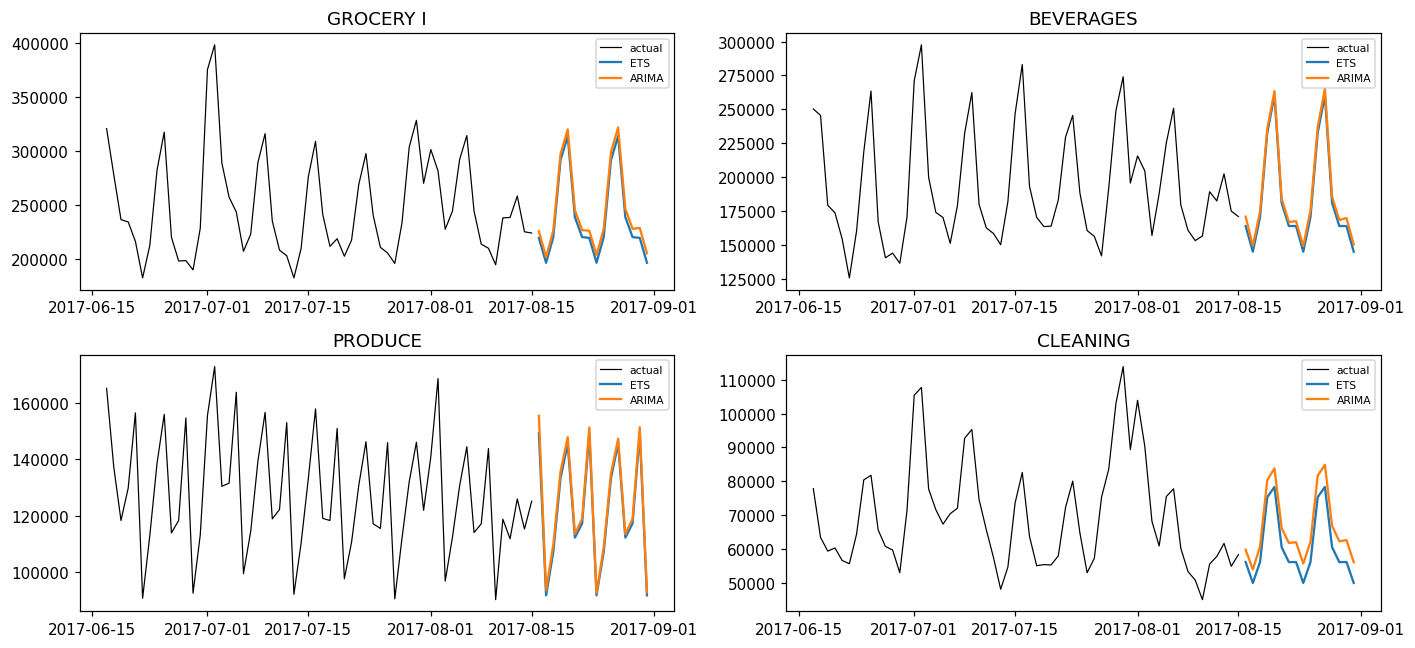


GROCERY I: ETS parameters {'smoothing_level': 0.827, 'smoothing_seasonal': 0.0}; trend used: None
GROCERY I: ARIMA order (1, 1, 1), promotion coefficient on log scale 0.013 (a 10% rise in items on promotion goes with about 0.1% more units)
ETS trend chosen by AIC across families: {'none': 31, 'damped additive': 2}
ETS level smoothing across families: median 0.49 (0 = slow to react, 1 = follows the latest day)
ARIMA promotion coefficients: positive in 31 of 33 families; median 0.013


In [6]:
## ---- 3b. Final fits, Kaggle forecasts, interpretation --------------------------
# ---- final fits through 2017-08-15 and the Kaggle test forecasts ----
t0 = time.time()
test_dates = pd.date_range(test.date.min(), test.date.max())
Pfut_test = np.log1p(test.groupby(["date", "family"]).onpromotion.sum().unstack("family").reindex(test_dates).fillna(0))[FAMS]
ets_t, ari_t, ets_models, ari_models, orders = family_forecasts(Y, P, Pfut_test, len(test_dates))
sh_t = store_shares(train.date.max())
pred_ets = to_store_level(ets_t, test_dates, sh_t, test)
pred_ari = to_store_level(ari_t, test_dates, sh_t, test)
for name, pred in (("A8_store_model1_ets.csv", pred_ets), ("A8_store_model2_arima.csv", pred_ari)):
    sub = pd.DataFrame({"id": test["id"].values, "sales": pred}); path = os.path.join(OUT_DIR, name)
    sub.to_csv(path, index=False); print("saved", path, sub.shape, "total units forecast:", f"{sub.sales.sum():,.0f}"); download(path)
print(f"final fits: {time.time() - t0:.0f} s; ARIMA orders chosen:", pd.Series(orders).value_counts().to_dict())

# Forecast plot for the four biggest families
big = fam_daily.iloc[-90:].sum().sort_values(ascending=False).index[:4]
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for a, f in zip(ax.flat, big):
    a.plot(fam_daily[f].iloc[-60:], c="k", lw=.8, label="actual")
    a.plot(test_dates, np.expm1(ets_t[f].values), label="ETS"); a.plot(test_dates, np.expm1(ari_t[f].values), label="ARIMA")
    a.set_title(f); a.legend(fontsize=7)
save_fig("A8_store_fig_forecast.png")
# Interpretation: ETS smoothing parameters and ARIMA promotion effect for the largest family
f0 = big[0]; e = ets_models[f0]; a_ = ari_models[f0]
ets_par = {k: float(e.params[k]) for k in ("smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend") if k in e.params and e.params[k] == e.params[k]}
promo_coef = float(a_.params.get(f0, np.nan))
print(f"\n{f0}: ETS parameters {({k: round(v, 3) for k, v in ets_par.items()})}; trend used: {e.model.trend}")
print(f"{f0}: ARIMA order {orders[f0]}, promotion coefficient on log scale {promo_coef:.3f} "
      f"(a 10% rise in items on promotion goes with about {(1.1 ** promo_coef - 1) * 100:.1f}% more units)")
ets_trend = pd.Series({f: ("damped additive" if m.model.trend else "none") for f, m in ets_models.items()}).value_counts()
print("ETS trend chosen by AIC across families:", ets_trend.to_dict())
alphas = pd.Series({f: m.params["smoothing_level"] for f, m in ets_models.items()})
promo_all = pd.Series({f: m.params.get(f, np.nan) for f, m in ari_models.items()})
print(f"ETS level smoothing across families: median {alphas.median():.2f} (0 = slow to react, 1 = follows the latest day)")
print(f"ARIMA promotion coefficients: positive in {int((promo_all > 0).sum())} of {promo_all.notna().sum()} families; median {promo_all.median():.3f}")
RESULTS["final"] = {"orders": {k: list(v) for k, v in orders.items()}, "largest_family": f0, "ets_params_largest": ets_par,
                    "ets_trend_largest": str(e.model.trend), "promo_coef_largest": promo_coef,
                    "alpha_median": float(alphas.median()), "promo_positive": int((promo_all > 0).sum()), "promo_n": int(promo_all.notna().sum()),
                    "promo_median": float(promo_all.median()), "total_units_ets": float(pred_ets.sum()), "total_units_arima": float(pred_ari.sum()),
                    "ets_trend_counts": ets_trend.to_dict()}

## Part 4. Assumption checks
Both models assume that, once trend, weekly seasonality, and (for ARIMA) promotions are accounted for, what is left over is unpredictable noise. The checks, on the residuals of the final fits:
* **Stationarity** (ARIMA): augmented Dickey-Fuller (ADF) and KPSS tests on the log series, before and after first differencing. The d = 1 in the model assumes one difference makes the series stationary.
* **No leftover autocorrelation** (both): Ljung-Box test at lags 7 and 14. Small p-values mean pattern is left in the residuals.
* **Normal residuals** (needed for prediction intervals, not for point forecasts): Jarque-Bera test and skewness.
* **Constant variance:** compare residual variance in the first and second halves of the fit period.

Share of families where each test flags a problem (0.05 level):
       lb7_reject  lb14_reject  jb_reject  median_skew  median_var_ratio
model                                                                   
ARIMA       0.212        0.424        1.0        0.553             0.954
ETS         0.909        0.848        1.0        0.558             1.017
Stationarity (share of families): {'adf_level_nonstationary': 0.303, 'adf_diff_nonstationary': 0.0, 'kpss_level_reject': 0.758, 'kpss_diff_reject': 0.0}


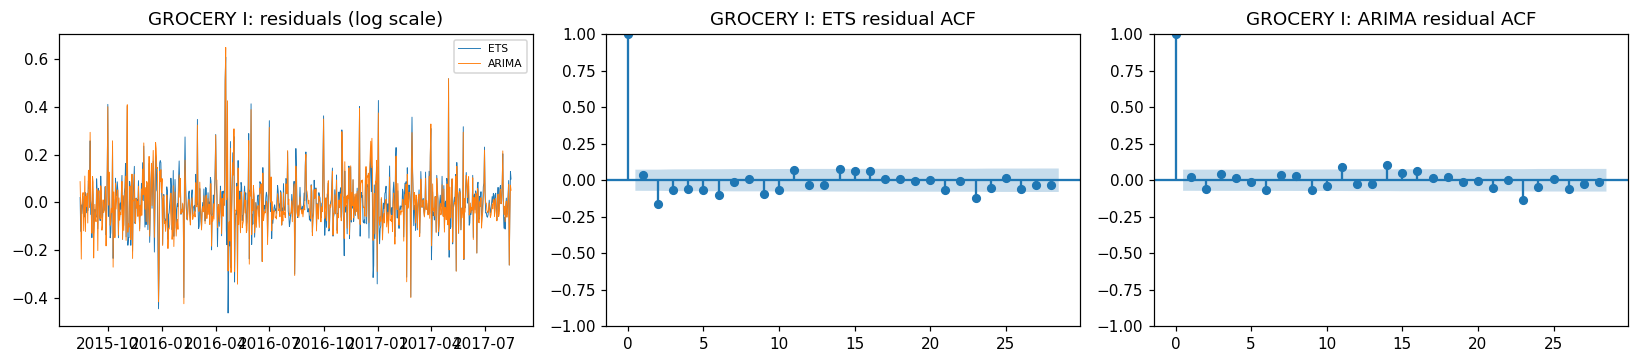

In [7]:
## ---- 4. Assumption checks: stationarity, Ljung-Box, normality, variance --------
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
import warnings as _w
rows = []
for f in FAMS:
    if f not in ets_models: continue
    y = Y[f]
    with _w.catch_warnings():
        _w.simplefilter("ignore")
        adf_lvl, adf_dif = adfuller(y, autolag="AIC")[1], adfuller(y.diff().dropna(), autolag="AIC")[1]
        kpss_lvl = kpss(y, regression="c", nlags="auto")[1]; kpss_dif = kpss(y.diff().dropna(), regression="c", nlags="auto")[1]
    for name, m in (("ETS", ets_models[f]), ("ARIMA", ari_models[f])):
        r = pd.Series(np.asarray(m.resid), index=y.index).iloc[14:]
        lb = acorr_ljungbox(r, lags=[7, 14], return_df=True)["lb_pvalue"]
        half = len(r) // 2
        rows.append({"family": f, "model": name, "adf_p_level": adf_lvl, "adf_p_diff": adf_dif, "kpss_p_level": kpss_lvl, "kpss_p_diff": kpss_dif,
                     "lb_p7": lb.iloc[0], "lb_p14": lb.iloc[1], "jb_p": stats.jarque_bera(r)[1], "skew": stats.skew(r),
                     # variance ratio (second half / first half); undefined when the first half is constant (a family with no early sales)
                     "var_ratio": (r.iloc[half:].var() / r.iloc[:half].var()) if r.iloc[:half].var() > 0 else np.nan})
chk = pd.DataFrame(rows)
summary = chk.groupby("model").agg(lb7_reject=("lb_p7", lambda s: (s < .05).mean()), lb14_reject=("lb_p14", lambda s: (s < .05).mean()),
                                    jb_reject=("jb_p", lambda s: (s < .05).mean()), median_skew=("skew", "median"),
                                    median_var_ratio=("var_ratio", "median"))
st = chk[chk.model == "ETS"]
stat_sum = {"adf_level_nonstationary": float((st.adf_p_level > .05).mean()), "adf_diff_nonstationary": float((st.adf_p_diff > .05).mean()),
            "kpss_level_reject": float((st.kpss_p_level < .05).mean()), "kpss_diff_reject": float((st.kpss_p_diff < .05).mean())}
print("Share of families where each test flags a problem (0.05 level):"); print(summary.round(3))
print("Stationarity (share of families):", {k: round(v, 3) for k, v in stat_sum.items()})
f0 = RESULTS["final"]["largest_family"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
r_e = pd.Series(np.asarray(ets_models[f0].resid), index=Y.index).iloc[14:]; r_a = pd.Series(np.asarray(ari_models[f0].resid), index=Y.index).iloc[14:]
ax[0].plot(r_e, lw=.6, label="ETS"); ax[0].plot(r_a, lw=.6, label="ARIMA"); ax[0].legend(fontsize=7); ax[0].set_title(f"{f0}: residuals (log scale)")
plot_acf(r_e, lags=28, ax=ax[1], title=f"{f0}: ETS residual ACF"); plot_acf(r_a, lags=28, ax=ax[2], title=f"{f0}: ARIMA residual ACF")
save_fig("A8_store_fig_resid.png")
RESULTS["checks"] = {"by_model": summary.round(4).to_dict(), "stationarity": stat_sum,
                     "largest_family": {m: chk[(chk.family == f0) & (chk.model == m)].iloc[0].drop(["family", "model"]).round(4).to_dict() for m in ("ETS", "ARIMA")}}

In [8]:
## ---- 5. Plain-language reading -------------------------------------------------
# ---- Part 5. Plain-language reading (generated from the numbers above) ----
V = RESULTS["validation"]["rmsle"]; Fn = RESULTS["final"]; S = RESULTS["series"]; Cc = RESULTS["checks"]
best = min(V, key=V.get)
print(f"* Holdout RMSLE: " + "; ".join(f"{k} {v:.4f}" for k, v in V.items()) + f". Best: {best}.")
_d = RESULTS["validation"]["spread"]["date"]; _w2 = RESULTS["validation"]["second_window"]["rmsle"]
_tie = abs(_d["diff_arima_minus_ets"]) < 2 * _d["diff_se"]
print(f"* ARIMA minus ETS, averaged over the 16 days: {_d['diff_arima_minus_ets']:+.4f} (SE {_d['diff_se']:.4f}); "
      + ("less than two standard errors, so the two models are statistically tied on this window. " if _tie else "more than two standard errors, so the gap is larger than day-to-day noise. ")
      + f"On the second window: ETS {_w2['Model 1: ETS']:.4f}, ARIMA {_w2['Model 2: ARIMA']:.4f}, baseline {_w2['Seasonal naive (baseline)']:.4f}.")
print(f"* Weekly seasonality is strong (STL strength {S['stl_seasonal_strength']:.2f}): weekends sell about "
      f"{(max(S['weekday_index'].values()) - 1) * 100:.0f}% above average, the weakest weekday about {(1 - min(S['weekday_index'].values())) * 100:.0f}% below.")
_a = Fn['alpha_median']
print(f"* ETS: median level smoothing {_a:.2f} across families (0 = slow to react, 1 = follows the latest day), so the level "
      + ("reacts quickly to recent days." if _a >= .3 else "moves slowly and leans on a long history." if _a < .1 else "adjusts at a moderate pace."))
print(f"* ARIMA: the promotion coefficient is positive for {Fn['promo_positive']} of {Fn['promo_n']} families (median {Fn['promo_median']:.3f} on the log scale).")
bm = Cc["by_model"]
print(f"* Residual checks: Ljung-Box flags leftover autocorrelation at lag 14 in {bm['lb14_reject']['ETS']:.0%} of families for ETS and "
      f"{bm['lb14_reject']['ARIMA']:.0%} for ARIMA; Jarque-Bera rejects normality in {bm['jb_reject']['ETS']:.0%} / {bm['jb_reject']['ARIMA']:.0%}, "
      "so point forecasts are usable but prediction intervals would be too narrow.")
_s = Cc['stationarity']
print(f"* Stationarity (log level vs first difference): ADF cannot reject a unit root in {_s['adf_level_nonstationary']:.0%} vs "
      f"{_s['adf_diff_nonstationary']:.0%} of families; KPSS rejects stationarity in {_s['kpss_level_reject']:.0%} vs {_s['kpss_diff_reject']:.0%}. "
      + ("The level fails at least one test in most families while the difference passes, which supports d = 1."
         if max(_s['adf_level_nonstationary'], _s['kpss_level_reject']) > .5 and max(_s['adf_diff_nonstationary'], _s['kpss_diff_reject']) < .1
         else "The evidence for differencing is mixed; d = 1 is kept, and the Ljung-Box checks show whether the differenced models left structure behind."))

* Holdout RMSLE: Seasonal naive (baseline) 0.6170; Model 1: ETS 0.4930; Model 2: ARIMA 0.4876. Best: Model 2: ARIMA.
* ARIMA minus ETS, averaged over the 16 days: -0.0053 (SE 0.0011); more than two standard errors, so the gap is larger than day-to-day noise. On the second window: ETS 0.4286, ARIMA 0.4294, baseline 0.5212.
* Weekly seasonality is strong (STL strength 0.73): weekends sell about 29% above average, the weakest weekday about 21% below.
* ETS: median level smoothing 0.49 across families (0 = slow to react, 1 = follows the latest day), so the level reacts quickly to recent days.
* ARIMA: the promotion coefficient is positive for 31 of 33 families (median 0.013 on the log scale).
* Residual checks: Ljung-Box flags leftover autocorrelation at lag 14 in 85% of families for ETS and 42% for ARIMA; Jarque-Bera rejects normality in 100% / 100%, so point forecasts are usable but prediction intervals would be too narrow.
* Stationarity (log level vs first difference): ADF cannot rejec

In [9]:
## ---- 6. Environment report and results JSON ------------------------------------
RESULTS_FILE = "A8_store_results.json"
# ---- Environment report (the Python equivalent of R's sessionInfo()) ----
import importlib, platform
VERSIONS = {"python": platform.python_version()}
for pkg in ("numpy", "pandas", "sklearn", "statsmodels", "scipy", "matplotlib", "ISLP"):
    try:
        VERSIONS[pkg] = importlib.import_module(pkg).__version__
    except Exception:
        VERSIONS[pkg] = "not installed"
print("Environment:", VERSIONS)
print(f"Total run time: {(time.time() - T0) / 60:.1f} min")
RESULTS["environment"] = VERSIONS

# ---- Results used in the paper (printed so they are saved in the notebook) ----
def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items() if not str(k).startswith("_")}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return _clean(o.tolist())
    if isinstance(o, (np.floating, np.integer, np.bool_)):
        return o.item()
    if isinstance(o, float) and o != o:
        return None
    return o
RESULTS = _clean(RESULTS)
with open(os.path.join(OUT_DIR, RESULTS_FILE), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("RESULTS_JSON_START")
print(json.dumps(RESULTS))
print("RESULTS_JSON_END")

Environment: {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'statsmodels': '0.15.0', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'ISLP': '0.6.0'}
Total run time: 19.8 min
RESULTS_JSON_START
{"data": {"n_train": 3000888, "n_test": 28512, "start": "2013-01-01", "end": "2017-08-15", "test_start": "2017-08-16", "test_end": "2017-08-31", "series": 1782, "families": 33, "stores": 54, "zero_share": 0.3129506999261552, "never_sell": 53, "missing_days": ["2013-12-25", "2014-12-25", "2015-12-25", "2016-12-25"], "sha256": {"train.csv": "99a1b7f4241821df10fa71f23abdd71c634f71f901e3cab1400c0f0c583f862c", "test.csv": "087ec1ecec76dbba9ea2adb48b8b2fd527c7c59adb82b0dfb9f6f82739400d26", "sample_submission.csv": "17505ec561d9bc64a3c10c3eb00474becf162d9053cebf014a58a6c82ed530c4"}}, "series": {"start": "2015-08-01", "n_days": 746, "weekday_index": {"0": 0.961, "1": 0.9001, "2": 0.942, "3": 0.7912, "4": 0.9292, "5": 1.1888, "6": 1.2877}, "stl_seasonal_strength": 0.73371830529